# Superstore Sales Data Analysis Using Python

## Project Overview

This project analyzes the Sample Superstore dataset using Python to understand sales performance, profitability, customer behavior, product performance, and regional sales.

The analysis uses Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn to clean, explore, analyze, and visualize the data.

## Objectives

- Analyze overall sales and profit performance.
- Identify the best-performing product categories and sub-categories.
- Analyze sales across different regions.
- Identify top customers and products.
- Analyze discounts and their impact on profitability.
- Identify products and areas generating losses.
- Extract meaningful business insights from the data.

## Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_excel('Sample - Superstore 2.xlsx')

In [6]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [7]:
df.shape

(9994, 21)

In [8]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [9]:
df.duplicated().sum()

np.int64(0)

In [12]:
#Checking unique values
df.nunique()

,0
Row ID,9994
Order ID,5009
Order Date,1237
Ship Date,1334
Ship Mode,4
Customer ID,793
Customer Name,793
Segment,3
Country,1
City,531


In [13]:
#Removing Duplicate Values
df = df.drop_duplicates()

In [14]:
#Convert Date Columns
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

In [16]:
#Total Sales
df['Sales'].sum()

np.float64(2297200.8603)

In [17]:
#Total profit
df['Profit'].sum()

np.float64(286397.0217)

In [18]:
#Total orders
df['Order ID'].nunique()

5009

In [19]:
#Average sales
df['Sales'].mean()

np.float64(229.85800083049827)

In [20]:
#Average profit
df['Profit'].mean()

np.float64(28.65689630778467)

In [21]:
#Profit Margin
(df['Profit'].sum() / df['Sales'].sum()) * 100

np.float64(12.467217240315605)

In [22]:
#Sales by category
df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

,Sales
Category,
Technology,836154.0330
Furniture,741999.7953
Office Supplies,719047.0320


In [23]:
#Profit by category
df.groupby('Category')['Profit'].sum().sort_values(ascending=False)

,Profit
Category,
Technology,145454.9481
Office Supplies,122490.8008
Furniture,18451.2728


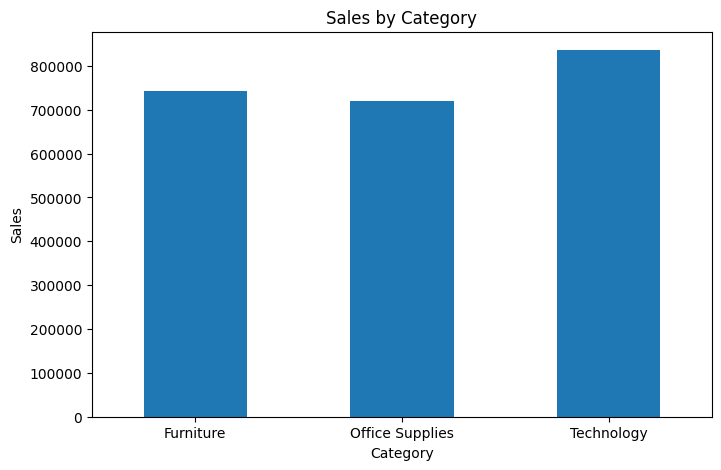

In [24]:
#Category sales visualisation
category_sales = df.groupby('Category')['Sales'].sum()

category_sales.plot(kind='bar', figsize=(8,5))

plt.title('Sales by Category')
plt.xlabel('Category')
plt.ylabel('Sales')
plt.xticks(rotation=0)
plt.show()

In [25]:
#Sales by Sub-Category
df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False)

,Sales
Sub-Category,
Phones,330007.0540
Chairs,328449.1030
Storage,223843.6080
Tables,206965.5320
Binders,203412.7330
Machines,189238.6310
Accessories,167380.3180
Copiers,149528.0300
Bookcases,114879.9963


In [26]:
#Profit by Sub-Category
df.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=False)

,Profit
Sub-Category,
Copiers,55617.8249
Phones,44515.7306
Accessories,41936.6357
Paper,34053.5693
Binders,30221.7633
Chairs,26590.1663
Storage,21278.8264
Appliances,18138.0054
Furnishings,13059.1436


In [27]:
#Top 10 Sub-Categories by Sales
df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False).head(10)

,Sales
Sub-Category,
Phones,330007.0540
Chairs,328449.1030
Storage,223843.6080
Tables,206965.5320
Binders,203412.7330
Machines,189238.6310
Accessories,167380.3180
Copiers,149528.0300
Bookcases,114879.9963


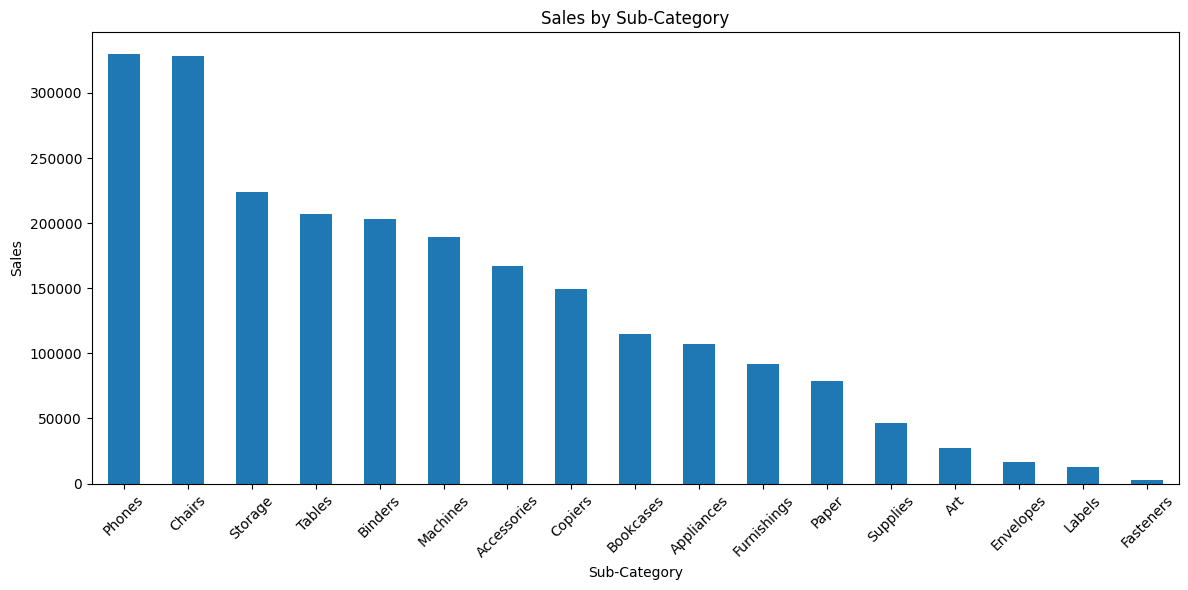

In [28]:
#Sub category visualisation
subcategory_sales = df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(12,6))

subcategory_sales.plot(kind='bar')

plt.title('Sales by Sub-Category')
plt.xlabel('Sub-Category')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
#Sales by region
df.groupby('Region')['Sales'].sum().sort_values(ascending=False)

,Sales
Region,
West,725457.8245
East,678781.2400
Central,501239.8908
South,391721.9050


In [30]:
#Profit by region
df.groupby('Region')['Profit'].sum().sort_values(ascending=False)

,Profit
Region,
West,108418.4489
East,91522.7800
South,46749.4303
Central,39706.3625


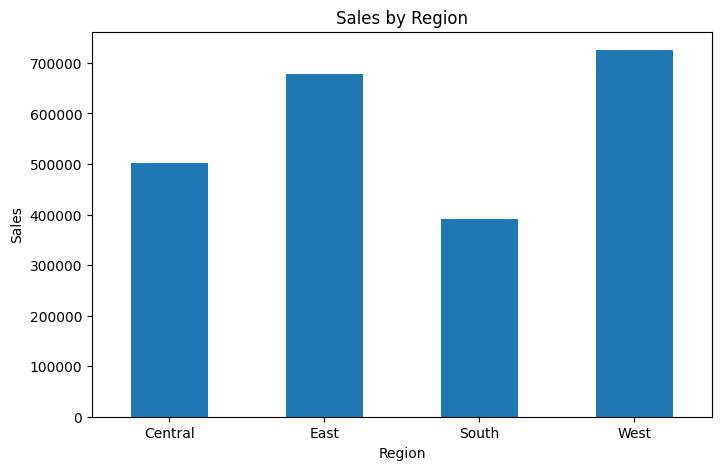

In [31]:
#Regional Sales Chart
region_sales = df.groupby('Region')['Sales'].sum()

plt.figure(figsize=(8,5))

region_sales.plot(kind='bar')

plt.title('Sales by Region')
plt.xlabel('Region')
plt.ylabel('Sales')
plt.xticks(rotation=0)
plt.show()

In [32]:
#Sales by Customer Segment
df.groupby('Segment')['Sales'].sum().sort_values(ascending=False)

,Sales
Segment,
Consumer,1.161401e+06
Corporate,7.061464e+05
Home Office,4.296531e+05


In [33]:
#Profit by Customer Segment
df.groupby('Segment')['Profit'].sum().sort_values(ascending=False)

,Profit
Segment,
Consumer,134119.2092
Corporate,91979.1340
Home Office,60298.6785


In [35]:
#Top 10 Customers by Sales
df.groupby('Customer Name')['Sales'].sum().sort_values(ascending=False).head(5)

,Sales
Customer Name,
Sean Miller,25043.050
Tamara Chand,19052.218
Raymond Buch,15117.339
Tom Ashbrook,14595.620
Adrian Barton,14473.571


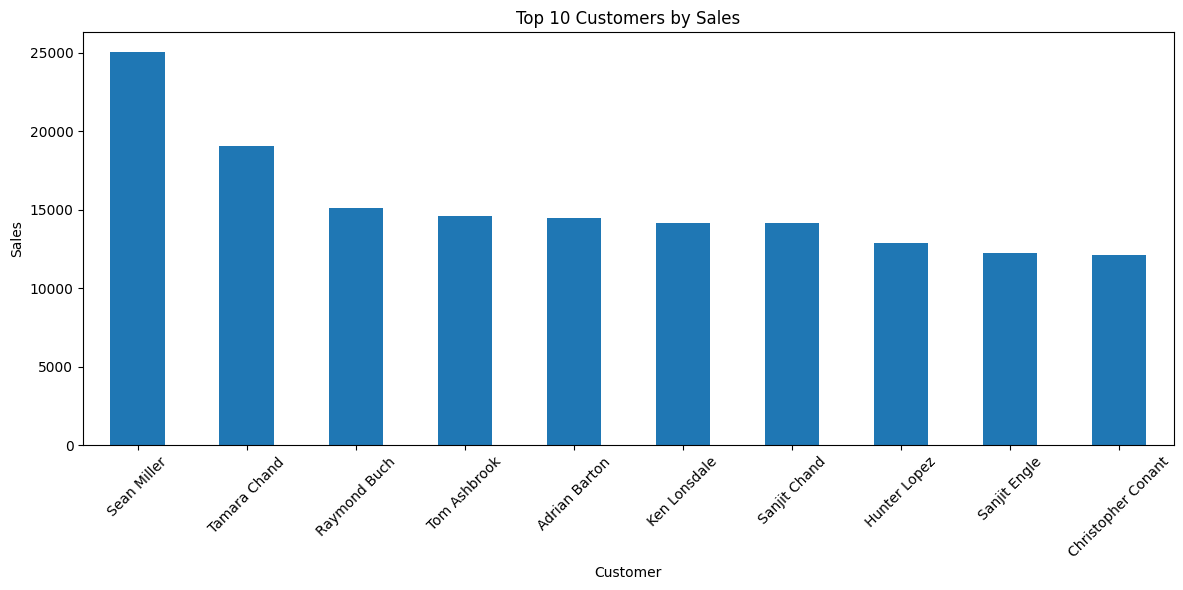

In [36]:
#Top 10 Customers Visualization
top_customers = df.groupby('Customer Name')['Sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))

top_customers.plot(kind='bar')

plt.title('Top 10 Customers by Sales')
plt.xlabel('Customer')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
#Top 10 Products by Sales
df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(10)

,Sales
Product Name,
Canon imageCLASS 2200 Advanced Copier,61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480
HON 5400 Series Task Chairs for Big and Tall,21870.576
GBC DocuBind TL300 Electric Binding System,19823.479
GBC Ibimaster 500 Manual ProClick Binding System,19024.500
Hewlett Packard LaserJet 3310 Copier,18839.686
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895
GBC DocuBind P400 Electric Binding System,17965.068


In [38]:
#Top 10 Products by Profit
df.groupby('Product Name')['Profit'].sum().sort_values(ascending=False).head(10)

,Profit
Product Name,
Canon imageCLASS 2200 Advanced Copier,25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,7753.0390
Hewlett Packard LaserJet 3310 Copier,6983.8836
Canon PC1060 Personal Laser Copier,4570.9347
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",4094.9766
Ativa V4110MDD Micro-Cut Shredder,3772.9461
"3D Systems Cube Printer, 2nd Generation, Magenta",3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System,3696.2820
Ibico EPK-21 Electric Binding System,3345.2823


In [39]:
#Loss-Making Products
product_profit = df.groupby('Product Name')['Profit'].sum()

product_profit[product_profit < 0].sort_values().head(10)

,Profit
Product Name,
Cubify CubeX 3D Printer Double Head Print,-8879.9704
Lexmark MX611dhe Monochrome Laser Printer,-4589.9730
Cubify CubeX 3D Printer Triple Head Print,-3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,-2876.1156
Bush Advantage Collection Racetrack Conference Table,-1934.3976
GBC DocuBind P400 Electric Binding System,-1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit,-1811.0784
Martin Yale Chadless Opener Electric Letter Opener,-1299.1836
Balt Solid Wood Round Tables,-1201.0581


In [41]:
#Profit by Discount
df.groupby('Discount')['Profit'].sum().sort_index()

,Profit
Discount,
0.00,320987.6032
0.10,9029.1770
0.15,1418.9915
0.20,90337.3060
0.30,-10369.2774
0.32,-2391.1377
0.40,-23057.0504
0.45,-2493.1111
0.50,-20506.4281


In [42]:
#Sales by Discount
df.groupby('Discount')['Sales'].sum().sort_index()

,Sales
Discount,
0.00,1.087908e+06
0.10,5.436935e+04
0.15,2.755852e+04
0.20,7.645944e+05
0.30,1.032267e+05
0.32,1.449346e+04
0.40,1.164178e+05
0.45,5.484974e+03
0.50,5.891854e+04


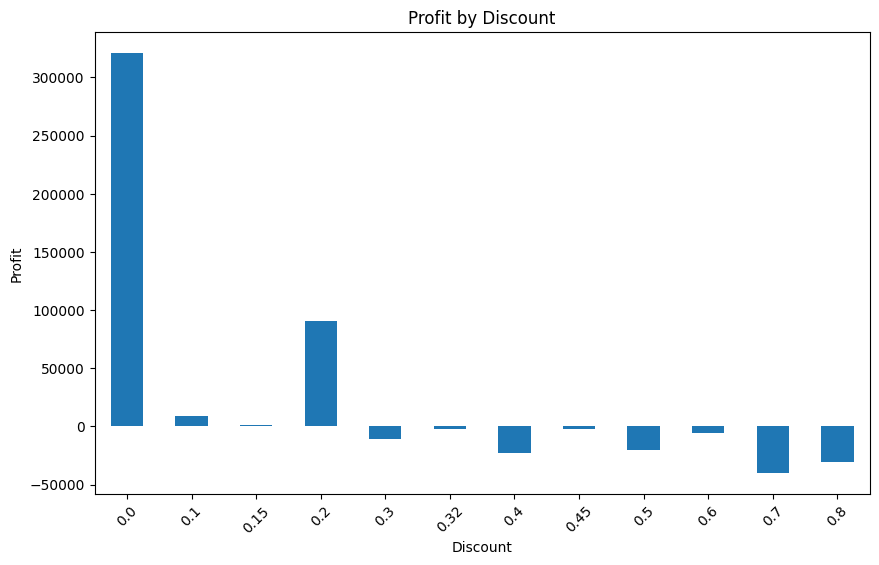

In [43]:
#Discount vs Profit Visualization
discount_profit = df.groupby('Discount')['Profit'].sum()

plt.figure(figsize=(10,6))

discount_profit.plot(kind='bar')

plt.title('Profit by Discount')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.xticks(rotation=45)
plt.show()

In [44]:
#Yearly Sales
df.groupby(df['Order Date'].dt.year)['Sales'].sum()

,Sales
Order Date,
2014,484247.4981
2015,470532.5090
2016,609205.5980
2017,733215.2552


In [45]:
#Yearly Profit
df.groupby(df['Order Date'].dt.year)['Profit'].sum()

,Profit
Order Date,
2014,49543.9741
2015,61618.6037
2016,81795.1743
2017,93439.2696


In [46]:
#monthly sales
df.groupby(df['Order Date'].dt.month)['Sales'].sum()

,Sales
Order Date,
1,94924.8356
2,59751.2514
3,205005.4888
4,137762.1286
5,155028.8117
6,152718.6793
7,147238.0970
8,159044.0630
9,307649.9457


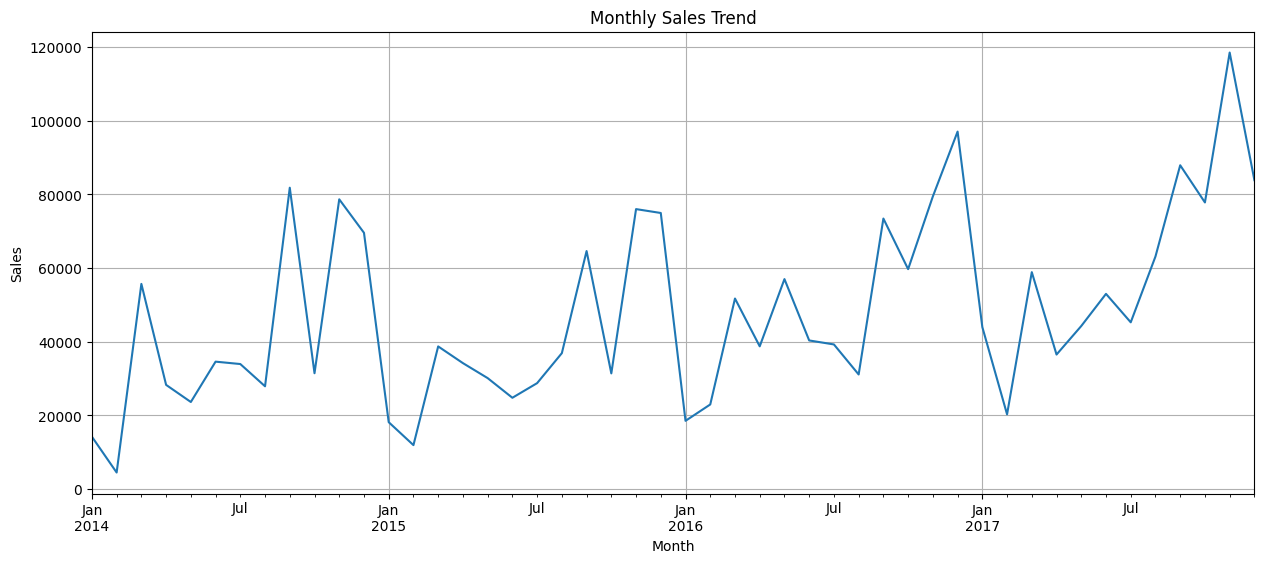

In [50]:
#Monthly Sales Trend
monthly_sales = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum()

monthly_sales.plot(figsize=(15,6))

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.grid()
plt.show()

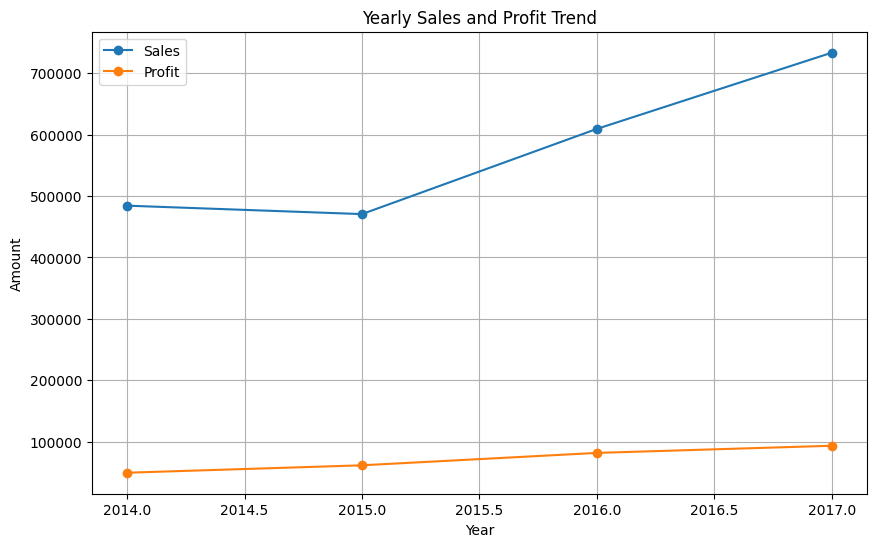

In [51]:
#How Sales and Profit changed over the years?
yearly_sales_profit = df.groupby(df['Order Date'].dt.year)[['Sales', 'Profit']].sum()

yearly_sales_profit.plot(kind='line', marker='o', figsize=(10, 6))

plt.title('Yearly Sales and Profit Trend')
plt.xlabel('Year')
plt.ylabel('Amount')
plt.legend(['Sales', 'Profit'])
plt.grid(True)
plt.show()

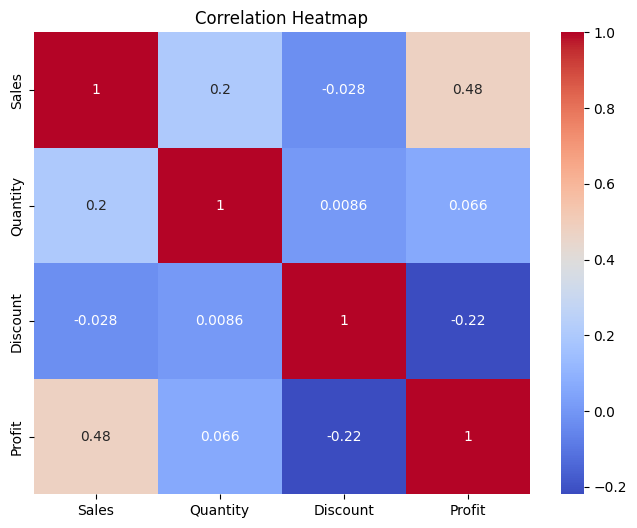

In [52]:
#Correlation heatmap
plt.figure(figsize=(8,6))

sns.heatmap(
    df[['Sales', 'Quantity', 'Discount', 'Profit']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()